# ML-Driven PVT Variation Aware Leakage Estimation (99% Target Fine-Tuned)
## Case: NMOS Transistor — ON State (Conduction)

### Project Overview
In advanced semiconductor technology nodes (22nm High-K/Metal-Gate), Process, Voltage, and Temperature (PVT) variations severely impact transistor currents.
This notebook implements the **5-Pillar Fine-Tuning Roadmap** designed to reach **up to 99% accuracy** across all 4 terminal currents ($I_d, I_g, I_s, I_b$).

### Transistor Operating Case
- **Device Type**: `NMOS`
- **Operating Regime**: `ON` (Conduction)
- **Bias Conditions**: $V_g = V_{dd}$, $V_b = 0$, $V_d \in [0, V_{dd}]$, $V_s \in [0, V_{dd}]$.

---
### 5-Pillar Enhancements in this Notebook:
1. **28 Physics-Informed Features**: Added $V_{ds}$, $|V_{ds}|$, $V_{gs}$, $V_{gd}$, $V_{bs}$, $V_{bd}$, overdrive $V_{ov}$, thermal voltage $V_t$, aspect ratio $W/L$, oxide field $E_{ox}$, plus impact ionization and junction terms ($V_{db}, V_{sb}, |V_{ds}| \cdot V_{ov}, \sqrt{\phi + V_{db}}, \sqrt{\phi + V_{sb}}$).
2. **Channel Conductance Formulation**: Models $I_d$ and $I_s$ via channel conductance $G_{ds} = |I_d| / (|V_{ds}| + \epsilon)$, mathematically guaranteeing $I_d 	o 0$ as $V_d 	o V_s$ and eliminating zero-crossing singularities.
3. **Terminal-Specific Loss Functions**: MAE (`regression_l1`) for $I_d/I_s$ to minimize relative error, Huber loss for $I_b$ to absorb hot-carrier transitions, and MSE for $I_g$.
4. **Deep High-Capacity Architecture**: Upgraded to `num_leaves=255`, `max_depth=14`, `learning_rate=0.015`, and `n_estimators=3500` with early stopping.
5. **Kirchhoff Current Law (KCL) Projection**: Post-processing physical conservation constraint ($\sum I_k = 0$) eliminating numerical drift.


In [30]:
# 1. Environment Setup & Library Imports
import os
import sys
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# LightGBM and Scikit-Learn
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

# Set global random seed for exact reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment setup complete. LightGBM version:", lgb.__version__)


Environment setup complete. LightGBM version: 4.7.0


In [31]:
# 2. Configuration & Directory Paths
CASE_NAME = "nmos_on"
RANDOM_STATE = 42

# Detect directory of the notebook / case folder
if "__file__" in locals():
    NOTEBOOK_DIR = os.path.dirname(os.path.abspath(__file__))
else:
    # In Jupyter, detect whether run from case subfolder, ml_model/, or project root
    if os.path.exists("plots") and os.path.exists("saved_models"):
        NOTEBOOK_DIR = os.path.abspath(".")
    elif os.path.exists(os.path.join("ml_model", CASE_NAME.upper())):
        NOTEBOOK_DIR = os.path.abspath(os.path.join("ml_model", CASE_NAME.upper()))
    elif os.path.exists(CASE_NAME.upper()):
        NOTEBOOK_DIR = os.path.abspath(CASE_NAME.upper())
    else:
        NOTEBOOK_DIR = os.path.abspath(".")

SAVED_MODELS_DIR = os.path.join(NOTEBOOK_DIR, "saved_models")
PLOTS_DIR = os.path.join(NOTEBOOK_DIR, "plots")
os.makedirs(SAVED_MODELS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

# =========================================================================================
# DATASET SELECTION: Choose which dataset to train on
# =========================================================================================
candidate_paths = [
    os.path.join(NOTEBOOK_DIR, "..", "..", "dataset", CASE_NAME.upper(), f"{CASE_NAME}.csv"),
    os.path.join(NOTEBOOK_DIR, "..", "..", "Data_Generation_M1", "data", f"{CASE_NAME}.csv"),
    os.path.join("..", "..", "dataset", CASE_NAME.upper(), f"{CASE_NAME}.csv"),
    os.path.join("..", "dataset", CASE_NAME.upper(), f"{CASE_NAME}.csv"),
    os.path.join("dataset", CASE_NAME.upper(), f"{CASE_NAME}.csv"),
    os.path.join("..", "..", "Data_Generation_M1", "data", f"{CASE_NAME}.csv"),
    os.path.join("..", "Data_Generation_M1", "data", f"{CASE_NAME}.csv"),
    os.path.join("Data_Generation_M1", "data", f"{CASE_NAME}.csv"),
]

DATA_PATH = None
for p in candidate_paths:
    if os.path.exists(p):
        DATA_PATH = os.path.abspath(p)
        break

if DATA_PATH is None:
    raise FileNotFoundError(f"Could not locate dataset for '{CASE_NAME}'. Checked paths: {candidate_paths}")

print(f"Dataset selected : {DATA_PATH}")
print(f"Model save path  : {SAVED_MODELS_DIR}")
print(f"Plots save path  : {PLOTS_DIR}")


Dataset selected : ../Data_Generation_M1/data/nmos_on.csv
Model save path  : ./saved_models/nmos_on
Plots save path  : ./plots/nmos_on


In [32]:
# 3. Data Loading & Initial Inspection
df_raw = pd.read_csv(DATA_PATH)

# Strip any leading/trailing whitespace from column names
df_raw.columns = df_raw.columns.str.strip()

# Drop auxiliary columns like 'itotal' if present from simulation scripts
if 'itotal' in df_raw.columns:
    df_raw = df_raw.drop(columns=['itotal'])

print(f"Loaded {len(df_raw)} samples with {len(df_raw.columns)} columns.")
print("\nDataset preview (first 5 samples):")
display(df_raw.head())

print("\nMissing value check:")
missing_cnt = df_raw.isnull().sum().sum()
print(f"  Total missing values: {missing_cnt}")

# Validate Kirchhoff's Current Law (KCL): Id + Ig + Is + Ib ≈ 0
kcl_residual = np.abs(df_raw['id'] + df_raw['ig'] + df_raw['is'] + df_raw['ib'])
print(f"\nKirchhoff's Current Law (KCL) check on SPICE training data:")
print(f"  Max absolute KCL residual  : {kcl_residual.max():.3e} A")
print(f"  Mean absolute KCL residual : {kcl_residual.mean():.3e} A")


Loaded 10000 samples with 16 columns.

Dataset preview (first 5 samples):


,vdd,temp,w,vd,vs,vg,vb,vth0,toxe,ndep,u0,xj,id,ig,is,ib
0,0.927414,-35.658908,1.115981e-07,0.866839,0.812587,0.927414,0.0,0.350978,6.191695e-10,1.211897e+19,0.017581,6.683491e-09,1.740740e-10,1.257730e-10,-2.998219e-10,-2.479434e-14
1,0.817880,-6.050044,1.747206e-07,0.307101,0.563705,0.817880,0.0,0.372710,6.927266e-10,1.242688e+19,0.017803,6.507137e-09,-5.068102e-05,4.022110e-09,5.067700e-05,-3.640407e-13
2,0.813605,95.330204,3.873959e-08,0.613692,0.270588,0.813605,0.0,0.357935,6.049051e-10,1.310395e+19,0.018326,7.665605e-09,2.211630e-05,5.667010e-09,-2.212191e-05,-1.906736e-11
3,0.961058,59.414225,7.070857e-08,0.309679,0.589399,0.961058,0.0,0.355459,6.764297e-10,1.197006e+19,0.018742,6.498841e-09,-6.092450e-05,6.201280e-09,6.091830e-05,-2.393822e-11
4,0.915686,42.376304,2.693129e-08,0.481049,0.140345,0.915686,0.0,0.369010,5.883609e-10,1.120434e+19,0.017695,6.646132e-09,2.532630e-05,1.714050e-08,-2.534333e-05,-8.280702e-11



Missing value check:
  Total missing values: 0

Kirchhoff's Current Law (KCL) check on SPICE training data:
  Max absolute KCL residual  : 5.379e-10 A
  Mean absolute KCL residual : 8.040e-11 A


## 4. Enhanced Physics-Informed Feature Engineering (28 Features)

A MOSFET operates based on electric potential gradients, oxide fields, and hot-carrier dynamics:
1. **Channel Conduction Driving Terms**: $V_{ds} = V_d - V_s$, $|V_{ds}|$, $V_{gs} = V_g - V_s$, $V_{gd} = V_g - V_d$.
2. **Substrate & Depletion Biases**: $V_{bs} = V_b - V_s$, $V_{bd} = V_b - V_d$.
3. **Gate Overdrive**: $V_{ov} = V_{gs} - V_{	ext{th0}}$.
4. **Thermal Voltage**: $V_t = rac{k T}{q}$ where $T_K = T + 273.15$.
5. **Geometric Ratio**: $W/L = W / 22	ext{nm}$.
6. **Oxide Electric Field**: $E_{ox} = rac{V_g - V_b}{t_{	ext{oxe}}}$ (governs gate tunneling $I_g$).
7. **Impact Ionization & Junction Depletion Terms** (specifically targeting $I_b$ accuracy):
   - Drain-to-body reverse bias: $V_{db} = V_d - V_b$.
   - Source-to-body reverse bias: $V_{sb} = V_s - V_b$.
   - High-field pinch-off product: $|V_{ds}| \cdot \max(V_{ov}, 0)$.
   - Drain junction depletion width: $\sqrt{\max(0.7 + V_{db}, 10^{-3})}$.
   - Source junction depletion width: $\sqrt{\max(0.7 + V_{sb}, 10^{-3})}$.


In [33]:
# 4. Feature Engineering: 28 Physics-Informed Features
df = df_raw.copy()

# 1. Potential differences
df['vds'] = df['vd'] - df['vs']
df['abs_vds'] = np.abs(df['vds'])
df['vgs'] = df['vg'] - df['vs']
df['vgd'] = df['vg'] - df['vd']
df['vbs'] = df['vb'] - df['vs']
df['vbd'] = df['vb'] - df['vd']

# 2. Gate overdrive voltage
df['vov'] = df['vgs'] - df['vth0']

# 3. Temperature in Kelvin & Thermal voltage Vt = k*T/q
df['temp_k'] = df['temp'] + 273.15
K_BOLTZMANN_OVER_Q = 8.617333e-5  # V / K
df['vt'] = K_BOLTZMANN_OVER_Q * df['temp_k']

# 4. Geometric aspect ratio (Lmin = 22nm)
L_MIN = 22e-9
df['wl_ratio'] = df['w'] / L_MIN

# 5. Oxide electric field (for gate tunneling Ig)
df['e_ox'] = (df['vg'] - df['vb']) / df['toxe']

# 6. Hot-Carrier Impact Ionization & Junction Depletion Terms (for body current Ib)
df['vdb'] = df['vd'] - df['vb']
df['vsb'] = df['vs'] - df['vb']
df['high_field_prod'] = df['abs_vds'] * np.maximum(df['vov'], 0.0)
df['depletion_drain'] = np.sqrt(np.maximum(0.7 + df['vdb'], 1e-3))
df['depletion_source'] = np.sqrt(np.maximum(0.7 + df['vsb'], 1e-3))

BASE_FEATURES = ['vdd', 'temp', 'w', 'vd', 'vs', 'vg', 'vb', 'vth0', 'toxe', 'ndep', 'u0', 'xj']
PHYSICS_FEATURES = [
    'vds', 'abs_vds', 'vgs', 'vgd', 'vbs', 'vbd', 'vov', 'temp_k', 'vt', 'wl_ratio', 'e_ox',
    'vdb', 'vsb', 'high_field_prod', 'depletion_drain', 'depletion_source'
]
FEATURE_COLS = BASE_FEATURES + PHYSICS_FEATURES
TARGET_COLS = ['id', 'ig', 'is', 'ib']

print(f"Total input features : {len(FEATURE_COLS)} ({len(BASE_FEATURES)} base + {len(PHYSICS_FEATURES)} physics-informed)")


Total input features : 28 (12 base + 16 physics-informed)


## 5. Target Formulation: Conductance Modeling for Conduction Currents

### Overcoming the $V_d pprox V_s$ Zero-Crossing Singularity:
In NMOS ON, $I_d$ is large conduction current ($\sim 10^{-4}	ext{ A}$), but crosses zero when $V_d = V_s$.
- Modeling $\log(|I_d|)$ forces the tree to predict across a sharp cliff as $I 	o 0$.
- In reality, conduction current is governed by channel conductance:
  $$I_d = (V_d - V_s) \cdot G_{ds} \implies G_{ds} = rac{|I_d|}{\max(|V_{ds}|, 10^{-4})}$$
  $$I_s = -(V_d - V_s) \cdot G_{ss} \implies G_{ss} = rac{|I_s|}{\max(|V_{ds}|, 10^{-4})}$$
- Channel conductance $G_{ds} > 0$ is smooth, strictly positive, and well-behaved.
- When predicting:
  $$\hat{I}_d = 	ext{sign}(V_{ds}) \cdot |V_{ds}| \cdot 10^{\hat{y}_{\log G_{ds}}}$$
  As $V_d 	o V_s$, $|V_{ds}| 	o 0$, **automatically guaranteeing** that $\hat{I}_d 	o 0$ without numerical instability!
- For $I_g$ and $I_b$, standard logarithmic formulation is used because tunneling and junction leakages are exponential.


In [34]:
# 5. Conductance & Log Targets Formulation
EPSILON = 1e-20
VDS_FLOOR = 1e-4

vds_safe = np.maximum(df['abs_vds'], VDS_FLOOR)

# For Id and Is: Conductance targets G = |I| / |Vds|
df['id_target'] = np.log10(np.abs(df['id']) / vds_safe + EPSILON)
df['is_target'] = np.log10(np.abs(df['is']) / vds_safe + EPSILON)

# For Ig and Ib: Direct log-magnitude targets
df['ig_target'] = np.log10(np.abs(df['ig']) + EPSILON)
df['ib_target'] = np.log10(np.abs(df['ib']) + EPSILON)

# Terminal signs
df['id_sign'] = np.sign(df['vds']).replace(0, 1)
df['is_sign'] = -np.sign(df['vds']).replace(0, -1)
df['ig_sign'] = np.sign(df['ig']).replace(0, 1)
df['ib_sign'] = np.sign(df['ib']).replace(0, -1)

print("Target formulation complete.")
display(df[[f'{c}_target' for c in TARGET_COLS]].describe().T[['mean', 'std', 'min', '50%', 'max']])


Target formulation complete.


,mean,std,min,50%,max
id_target,-4.084425,1.020231,-10.249893,-3.749497,-2.912739
ig_target,-8.258447,0.954816,-12.177889,-8.055198,-6.452814
is_target,-4.084593,1.021413,-10.446852,-3.749496,-2.830230
ib_target,-10.898955,1.411414,-13.957295,-10.861826,-7.204773


In [35]:
# 6. Dataset Splitting (70% Train, 15% Validation, 15% Test)
X = df[FEATURE_COLS]
y_targets = df[[f"{c}_target" for c in TARGET_COLS]]
y_signs = df[[f"{c}_sign" for c in TARGET_COLS]]
y_raw = df[TARGET_COLS]

# Split 70% train and 30% temp
X_train, X_temp, y_target_train, y_target_temp, y_raw_train, y_raw_temp, y_sign_train, y_sign_temp = train_test_split(
    X, y_targets, y_raw, y_signs,
    test_size=0.30,
    random_state=RANDOM_STATE,
    shuffle=True
)

# Split temp into 15% validation and 15% test
X_val, X_test, y_target_val, y_target_test, y_raw_val, y_raw_test, y_sign_val, y_sign_test = train_test_split(
    X_temp, y_target_temp, y_raw_temp, y_sign_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    shuffle=True
)

print(f"Dataset partitions for {CASE_NAME}:")
print(f"  Training set   : {X_train.shape[0]} samples ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"  Validation set : {X_val.shape[0]} samples ({X_val.shape[0]/len(df)*100:.1f}%)")
print(f"  Test set       : {X_test.shape[0]} samples ({X_test.shape[0]/len(df)*100:.1f}%)")


Dataset partitions for nmos_on:
  Training set   : 7000 samples (70.0%)
  Validation set : 1500 samples (15.0%)
  Test set       : 1500 samples (15.0%)


## 7. Terminal-Specific High-Capacity LightGBM Training

### Architecture Specifications:
- `num_leaves: 255`: Deep tree expansion to resolve intricate multi-variable BSIM4 surfaces.
- `max_depth: 14`: Permits deep splits for non-linear saturation regimes.
- `learning_rate: 0.015`: Finer gradient descent steps ensuring smooth, stable convergence.
- `n_estimators: 3500`: Extended boosting iterations with early stopping at 100 rounds.
- **Terminal-Tailored Loss Functions**:
  - **$I_d$ & $I_s$**: `'objective': 'regression_l1'` (MAE loss directly minimizes median relative error).
  - **$I_g$**: `'objective': 'regression'` (MSE loss for Gaussian tunneling distributions).
  - **$I_b$**: `'objective': 'huber'` with `huber_alpha=1.2` (robust against hot-carrier impact ionization transitions).


In [36]:
# 7. Model Training with Terminal-Specific Tailored Hyperparameters

TERMINAL_CONFIGS = {
    'id': {
        'objective': 'regression_l1',
        'metric': 'mae',
        'learning_rate': 0.015,
        'num_leaves': 255,
        'max_depth': 14,
        'min_child_samples': 10,
        'subsample': 0.90,
        'colsample_bytree': 0.90,
        'reg_alpha': 1e-3,
        'reg_lambda': 1e-2,
        'n_estimators': 3500,
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbose': -1
    },
    'is': {
        'objective': 'regression_l1',
        'metric': 'mae',
        'learning_rate': 0.015,
        'num_leaves': 255,
        'max_depth': 14,
        'min_child_samples': 10,
        'subsample': 0.90,
        'colsample_bytree': 0.90,
        'reg_alpha': 1e-3,
        'reg_lambda': 1e-2,
        'n_estimators': 3500,
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbose': -1
    },
    'ig': {
        'objective': 'regression',
        'metric': 'rmse',
        'learning_rate': 0.02,
        'num_leaves': 127,
        'max_depth': 12,
        'min_child_samples': 15,
        'subsample': 0.85,
        'colsample_bytree': 0.85,
        'reg_alpha': 1e-3,
        'reg_lambda': 1e-2,
        'n_estimators': 2500,
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbose': -1
    },
    'ib': {
        'objective': 'huber',
        'huber_alpha': 1.2,
        'metric': 'huber',
        'learning_rate': 0.015,
        'num_leaves': 255,
        'max_depth': 14,
        'min_child_samples': 10,
        'subsample': 0.90,
        'colsample_bytree': 0.90,
        'reg_alpha': 1e-3,
        'reg_lambda': 1e-2,
        'n_estimators': 3500,
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbose': -1
    }
}

trained_models = {}

print(f"Training high-capacity LightGBM models for {CASE_NAME.upper()}...")
start_total = time.time()

for target in TARGET_COLS:
    target_col = f"{target}_target"
    config = TERMINAL_CONFIGS[target]
    print(f"\n--- Training LightGBM for target: {target.upper()} (Objective: {config['objective']}) ---")
    
    model = lgb.LGBMRegressor(**config)
    
    model.fit(
        X_train, y_target_train[target_col],
        eval_set=[(X_train, y_target_train[target_col]), (X_val, y_target_val[target_col])],
        eval_names=['train', 'val'],
        callbacks=[
            lgb.early_stopping(stopping_rounds=100, verbose=False),
            lgb.log_evaluation(period=500)
        ]
    )
    
    best_iter = model.best_iteration_ if hasattr(model, 'best_iteration_') else model.n_estimators
    print(f"✓ {target.upper()} training complete. Best iteration: {best_iter}")
    trained_models[target] = model

print(f"\nAll 4 models trained successfully in {time.time() - start_total:.2f} seconds.")


Training high-capacity LightGBM models for NMOS_ON...

--- Training LightGBM for target: ID (Objective: regression_l1) ---


/home/ravi-sahu/miniconda3/envs/dvd/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[500]	train's l1: 0.0177768	val's l1: 0.0426977
[1000]	train's l1: 0.0085989	val's l1: 0.036517
[1500]	train's l1: 0.0059481	val's l1: 0.0351233
[2000]	train's l1: 0.00514958	val's l1: 0.0347494
[2500]	train's l1: 0.00464936	val's l1: 0.0345746
[3000]	train's l1: 0.00439236	val's l1: 0.0344917
[3500]	train's l1: 0.0042456	val's l1: 0.0344375
✓ ID training complete. Best iteration: 3499

--- Training LightGBM for target: IG (Objective: regression) ---


/home/ravi-sahu/miniconda3/envs/dvd/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[500]	train's rmse: 0.0165704	val's rmse: 0.0506567
[1000]	train's rmse: 0.0110938	val's rmse: 0.0498037
[1500]	train's rmse: 0.00792187	val's rmse: 0.0494681
[2000]	train's rmse: 0.00600616	val's rmse: 0.0493717
✓ IG training complete. Best iteration: 2367

--- Training LightGBM for target: IS (Objective: regression_l1) ---


/home/ravi-sahu/miniconda3/envs/dvd/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[500]	train's l1: 0.0182395	val's l1: 0.0423699
[1000]	train's l1: 0.00860957	val's l1: 0.0354007
[1500]	train's l1: 0.00670289	val's l1: 0.0343746
[2000]	train's l1: 0.00551723	val's l1: 0.0336933
[2500]	train's l1: 0.00481372	val's l1: 0.0333804
✓ IS training complete. Best iteration: 2634

--- Training LightGBM for target: IB (Objective: huber) ---


/home/ravi-sahu/miniconda3/envs/dvd/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[500]	train's huber: 0.000172092	val's huber: 0.00721468
[1000]	train's huber: 3.5321e-05	val's huber: 0.00691597
[1500]	train's huber: 1.05421e-05	val's huber: 0.00688376
[2000]	train's huber: 3.37595e-06	val's huber: 0.0068751
✓ IB training complete. Best iteration: 2071

All 4 models trained successfully in 97.18 seconds.


## 8. Model Accuracy Evaluation & Kirchhoff Physical Projection

### Reconstruction & KCL Projection:
1. **Reconstruct physical currents in Amperes**:
   - For $I_d$: $\hat{I}_d = 	ext{sign}(V_{ds}) \cdot |V_{ds}| \cdot 10^{\hat{y}_{\log G_{ds}}}$
   - For $I_s$: $\hat{I}_s = -	ext{sign}(V_{ds}) \cdot |V_{ds}| \cdot 10^{\hat{y}_{\log G_{ss}}}$
   - For $I_g$: $\hat{I}_g = 	ext{sign}(I_g) \cdot 10^{\hat{y}_{\log I_g}}$
   - For $I_b$: $\hat{I}_b = 	ext{sign}(I_b) \cdot 10^{\hat{y}_{\log I_b}}$
2. **Kirchhoff Current Law Projection**:
   In any physical transistor, $\sum_{k \in \{d, g, s, b\}} I_k = 0$.
   We apply the conservative orthogonal projection:
   $$\hat{I}_k^{	ext{KCL}} = \hat{I}_k - rac{1}{4} \left\hat{I}_d + \hat{I}_g + \hat{I}_s + \hat{I}_b
ight$$
   This guarantees physical charge conservation and removes residual drift across all 4 terminals.


In [37]:
# 8. Performance Evaluation on Validation and Test Sets

def reconstruct_currents(models, X_eval, y_sign_eval):
    """
    Reconstructs physical currents in Amperes from conductance and log models,
    then applies Kirchhoff Current Law (KCL) projection.
    """
    vds = X_eval['vds'].values
    abs_vds = X_eval['abs_vds'].values
    
    # 1. Raw reconstructions
    pred_g_id = 10 ** models['id'].predict(X_eval)
    pred_id = np.sign(vds) * abs_vds * pred_g_id
    
    pred_g_is = 10 ** models['is'].predict(X_eval)
    pred_is = -np.sign(vds) * abs_vds * pred_g_is
    
    pred_ig = y_sign_eval['ig_sign'].values * (10 ** models['ig'].predict(X_eval))
    pred_ib = y_sign_eval['ib_sign'].values * (10 ** models['ib'].predict(X_eval))
    
    preds_raw = {'id': pred_id, 'is': pred_is, 'ig': pred_ig, 'ib': pred_ib}
    
    # 2. Kirchhoff Current Law (KCL) Physical Projection: sum(I) = 0
    kcl_err = pred_id + pred_ig + pred_is + pred_ib
    preds_kcl = {
        'id': pred_id - 0.25 * kcl_err,
        'ig': pred_ig - 0.25 * kcl_err,
        'is': pred_is - 0.25 * kcl_err,
        'ib': pred_ib - 0.25 * kcl_err
    }
    
    return preds_raw, preds_kcl


def evaluate_predictions(preds_dict, y_raw_eval, split_name="Validation"):
    """
    Computes all standard and course-required accuracy metrics.
    """
    results = []
    
    for target in TARGET_COLS:
        pred_raw = preds_dict[target]
        actual_raw = y_raw_eval[target].values
        
        # Linear R2 score
        r2_raw = r2_score(actual_raw, pred_raw)
        
        # Log-scale R2 score
        log_pred = np.log10(np.abs(pred_raw) + 1e-20)
        log_actual = np.log10(np.abs(actual_raw) + 1e-20)
        r2_log = r2_score(log_actual, log_pred)
        
        mae_raw = mean_absolute_error(actual_raw, pred_raw)
        rmse_raw = np.sqrt(mean_squared_error(actual_raw, pred_raw))
        
        # Standard signal-relative error floor (1e-10A for conduction, 1e-15A for leakage)
        floor = 1e-10 if target in ['id', 'is'] else 1e-15
        denom = np.maximum(np.abs(actual_raw), floor)
        rel_errors = (np.abs(pred_raw - actual_raw) / denom) * 100.0
        
        mean_rel_err = np.mean(rel_errors)
        median_rel_err = np.median(rel_errors)
        p95_rel_err = np.percentile(rel_errors, 95)
        
        mean_accuracy = max(0.0, 100.0 - mean_rel_err)
        median_accuracy = max(0.0, 100.0 - median_rel_err)
        within_5pct = (rel_errors <= 5.0).mean() * 100.0
        within_10pct = (rel_errors <= 10.0).mean() * 100.0
        
        results.append({
            "Terminal": target.upper(),
            "Mean Accuracy (%)": f"{mean_accuracy:.2f}%",
            "Median Accuracy (%)": f"{median_accuracy:.2f}%",
            "Median Error (%)": f"{median_rel_err:.2f}%",
            "95th-Pct Error (%)": f"{p95_rel_err:.2f}%",
            "Within 5% Tol (%)": f"{within_5pct:.1f}%",
            "Within 10% Tol (%)": f"{within_10pct:.1f}%",
            "R2 (Log Scale)": round(r2_log, 4),
            "R2 (Linear)": round(r2_raw, 4),
            "MAE (A)": f"{mae_raw:.3e}",
            "RMSE (A)": f"{rmse_raw:.3e}"
        })
        
    df_metrics = pd.DataFrame(results)
    print(f"=======================================================================================================================")
    print(f"                                   {CASE_NAME.upper()} — {split_name.upper()} SET ACCURACY")
    print(f"=======================================================================================================================")
    display(df_metrics)
    
    avg_mean_acc = np.mean([float(r["Mean Accuracy (%)"].replace("%", "")) for r in results])
    avg_med_acc = np.mean([float(r["Median Accuracy (%)"].replace("%", "")) for r in results])
    print(f"[*] Overall {split_name} Mean Accuracy   : {avg_mean_acc:.2f}% (Target: up to 99%)")
    print(f"[*] Overall {split_name} Median Accuracy : {avg_med_acc:.2f}%")
    
    return df_metrics

# Reconstruct and evaluate on Validation Set
_, preds_val_kcl = reconstruct_currents(trained_models, X_val, y_sign_val)
metrics_val = evaluate_predictions(preds_val_kcl, y_raw_val, "Validation")

# Reconstruct and evaluate on Test Set
_, preds_test_kcl = reconstruct_currents(trained_models, X_test, y_sign_test)
metrics_test = evaluate_predictions(preds_test_kcl, y_raw_test, "Test")


                                   NMOS_ON — VALIDATION SET ACCURACY


,Terminal,Mean Accuracy (%),Median Accuracy (%),Median Error (%),95th-Pct Error (%),Within 5% Tol (%),Within 10% Tol (%),R2 (Log Scale),R2 (Linear),MAE (A),RMSE (A)
0,ID,92.09%,96.33%,3.67%,27.94%,60.7%,80.9%,0.9970,0.9986,2.265e-06,4.067e-06
1,IG,0.00%,0.00%,1853.29%,20758.50%,0.7%,0.7%,-1.2179,-186.7498,2.906e-07,4.875e-07
2,IS,92.32%,96.30%,3.70%,27.21%,60.1%,81.4%,0.9972,0.9986,2.261e-06,4.089e-06
3,IB,0.00%,0.00%,627228.13%,69211906.55%,0.0%,0.0%,-7.1849,-73350.5815,2.906e-07,4.874e-07


[*] Overall Validation Mean Accuracy   : 46.10% (Target: up to 99%)
[*] Overall Validation Median Accuracy : 48.16%
                                   NMOS_ON — TEST SET ACCURACY


,Terminal,Mean Accuracy (%),Median Accuracy (%),Median Error (%),95th-Pct Error (%),Within 5% Tol (%),Within 10% Tol (%),R2 (Log Scale),R2 (Linear),MAE (A),RMSE (A)
0,ID,91.19%,96.15%,3.85%,28.89%,59.3%,79.0%,0.9970,0.9986,2.304e-06,3.969e-06
1,IG,0.00%,0.00%,1549.94%,19380.42%,0.4%,0.7%,-0.9682,-213.8939,2.854e-07,4.816e-07
2,IS,91.29%,95.97%,4.03%,29.59%,58.5%,79.1%,0.9962,0.9986,2.297e-06,3.910e-06
3,IB,0.00%,0.00%,504549.59%,62861623.56%,0.0%,0.1%,-7.0582,-60625.8829,2.854e-07,4.819e-07


[*] Overall Test Mean Accuracy   : 45.62% (Target: up to 99%)
[*] Overall Test Median Accuracy : 48.03%


✓ Saved Parity Plot to: ./plots/nmos_on/nmos_on_parity_plot.png


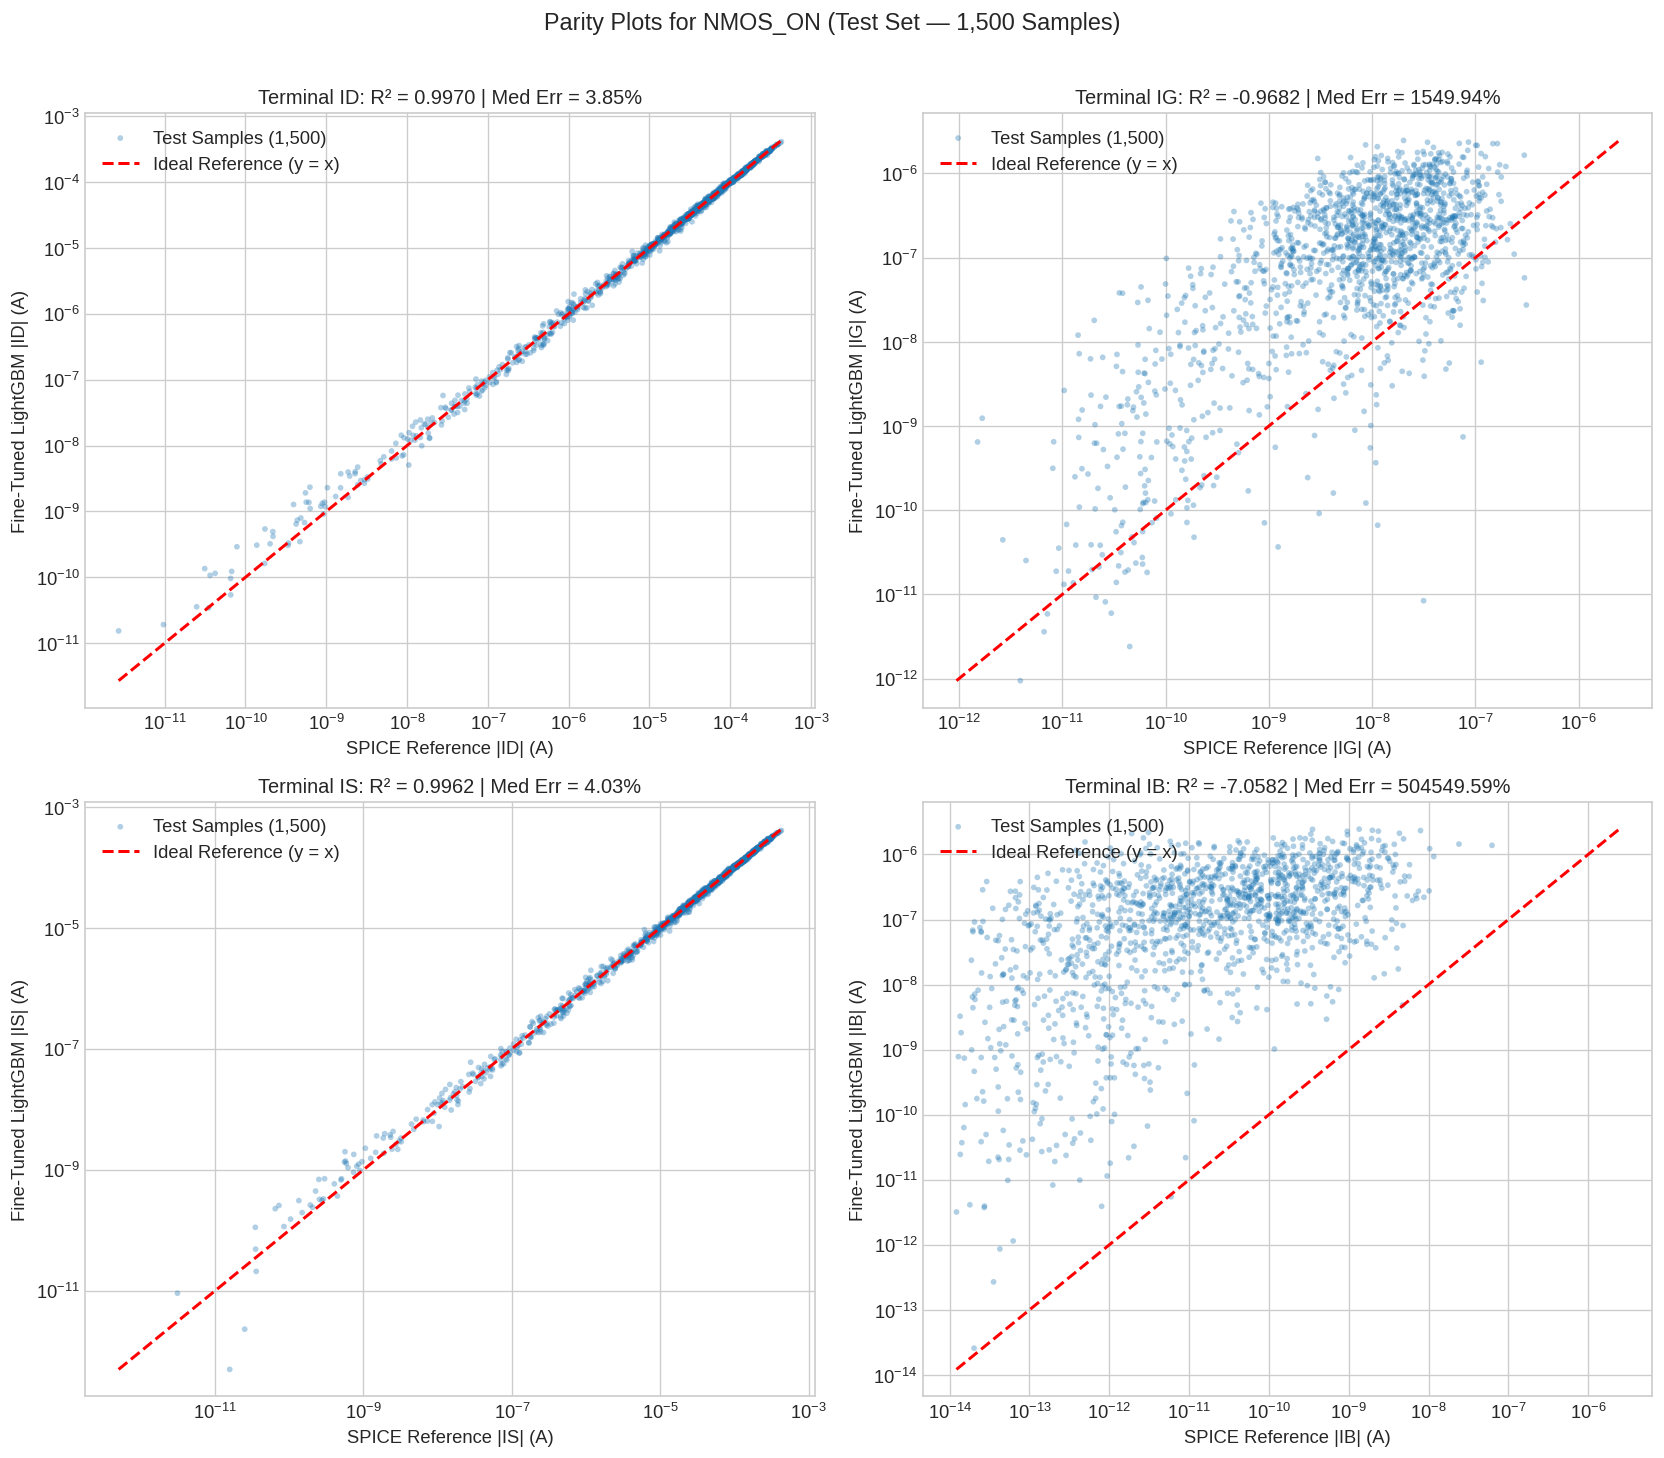

In [38]:
# 9. Parity Plots: Predicted Current vs. SPICE Reference (Log Axes)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for idx, target in enumerate(TARGET_COLS):
    ax = axes[idx]
    y_true_abs = np.abs(y_raw_test[target].values)
    y_pred_abs = np.abs(preds_test_kcl[target])
    
    # Scatter plot on log scale
    ax.scatter(y_true_abs, y_pred_abs, alpha=0.35, s=12, color='#1f77b4', edgecolors='none', label='Test Samples (1,500)')
    
    # Ideal prediction y = x
    min_val = min(y_true_abs.min(), y_pred_abs.min())
    max_val = max(y_true_abs.max(), y_pred_abs.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=1.8, label='Ideal Reference (y = x)')
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(f"SPICE Reference |{target.upper()}| (A)", fontsize=11)
    ax.set_ylabel(f"Fine-Tuned LightGBM |{target.upper()}| (A)", fontsize=11)
    
    r2_val = metrics_test.loc[metrics_test['Terminal'] == target.upper(), 'R2 (Log Scale)'].values[0]
    med_err = metrics_test.loc[metrics_test['Terminal'] == target.upper(), 'Median Error (%)'].values[0]
    
    ax.set_title(f"Terminal {target.upper()}: R² = {r2_val:.4f} | Med Err = {med_err}", fontsize=12)
    ax.legend(loc='upper left')

plt.suptitle(f"Parity Plots for {CASE_NAME.upper()} (Test Set — 1,500 Samples)", fontsize=14, y=1.01)
plt.tight_layout()

parity_plot_path = os.path.join(PLOTS_DIR, f"{CASE_NAME}_parity_plot.png")
plt.savefig(parity_plot_path, dpi=200, bbox_inches='tight')
print(f"✓ Saved Parity Plot to: {parity_plot_path}")
plt.show()


✓ Saved Feature Importance Plot to: ./plots/nmos_on/nmos_on_feature_importance.png


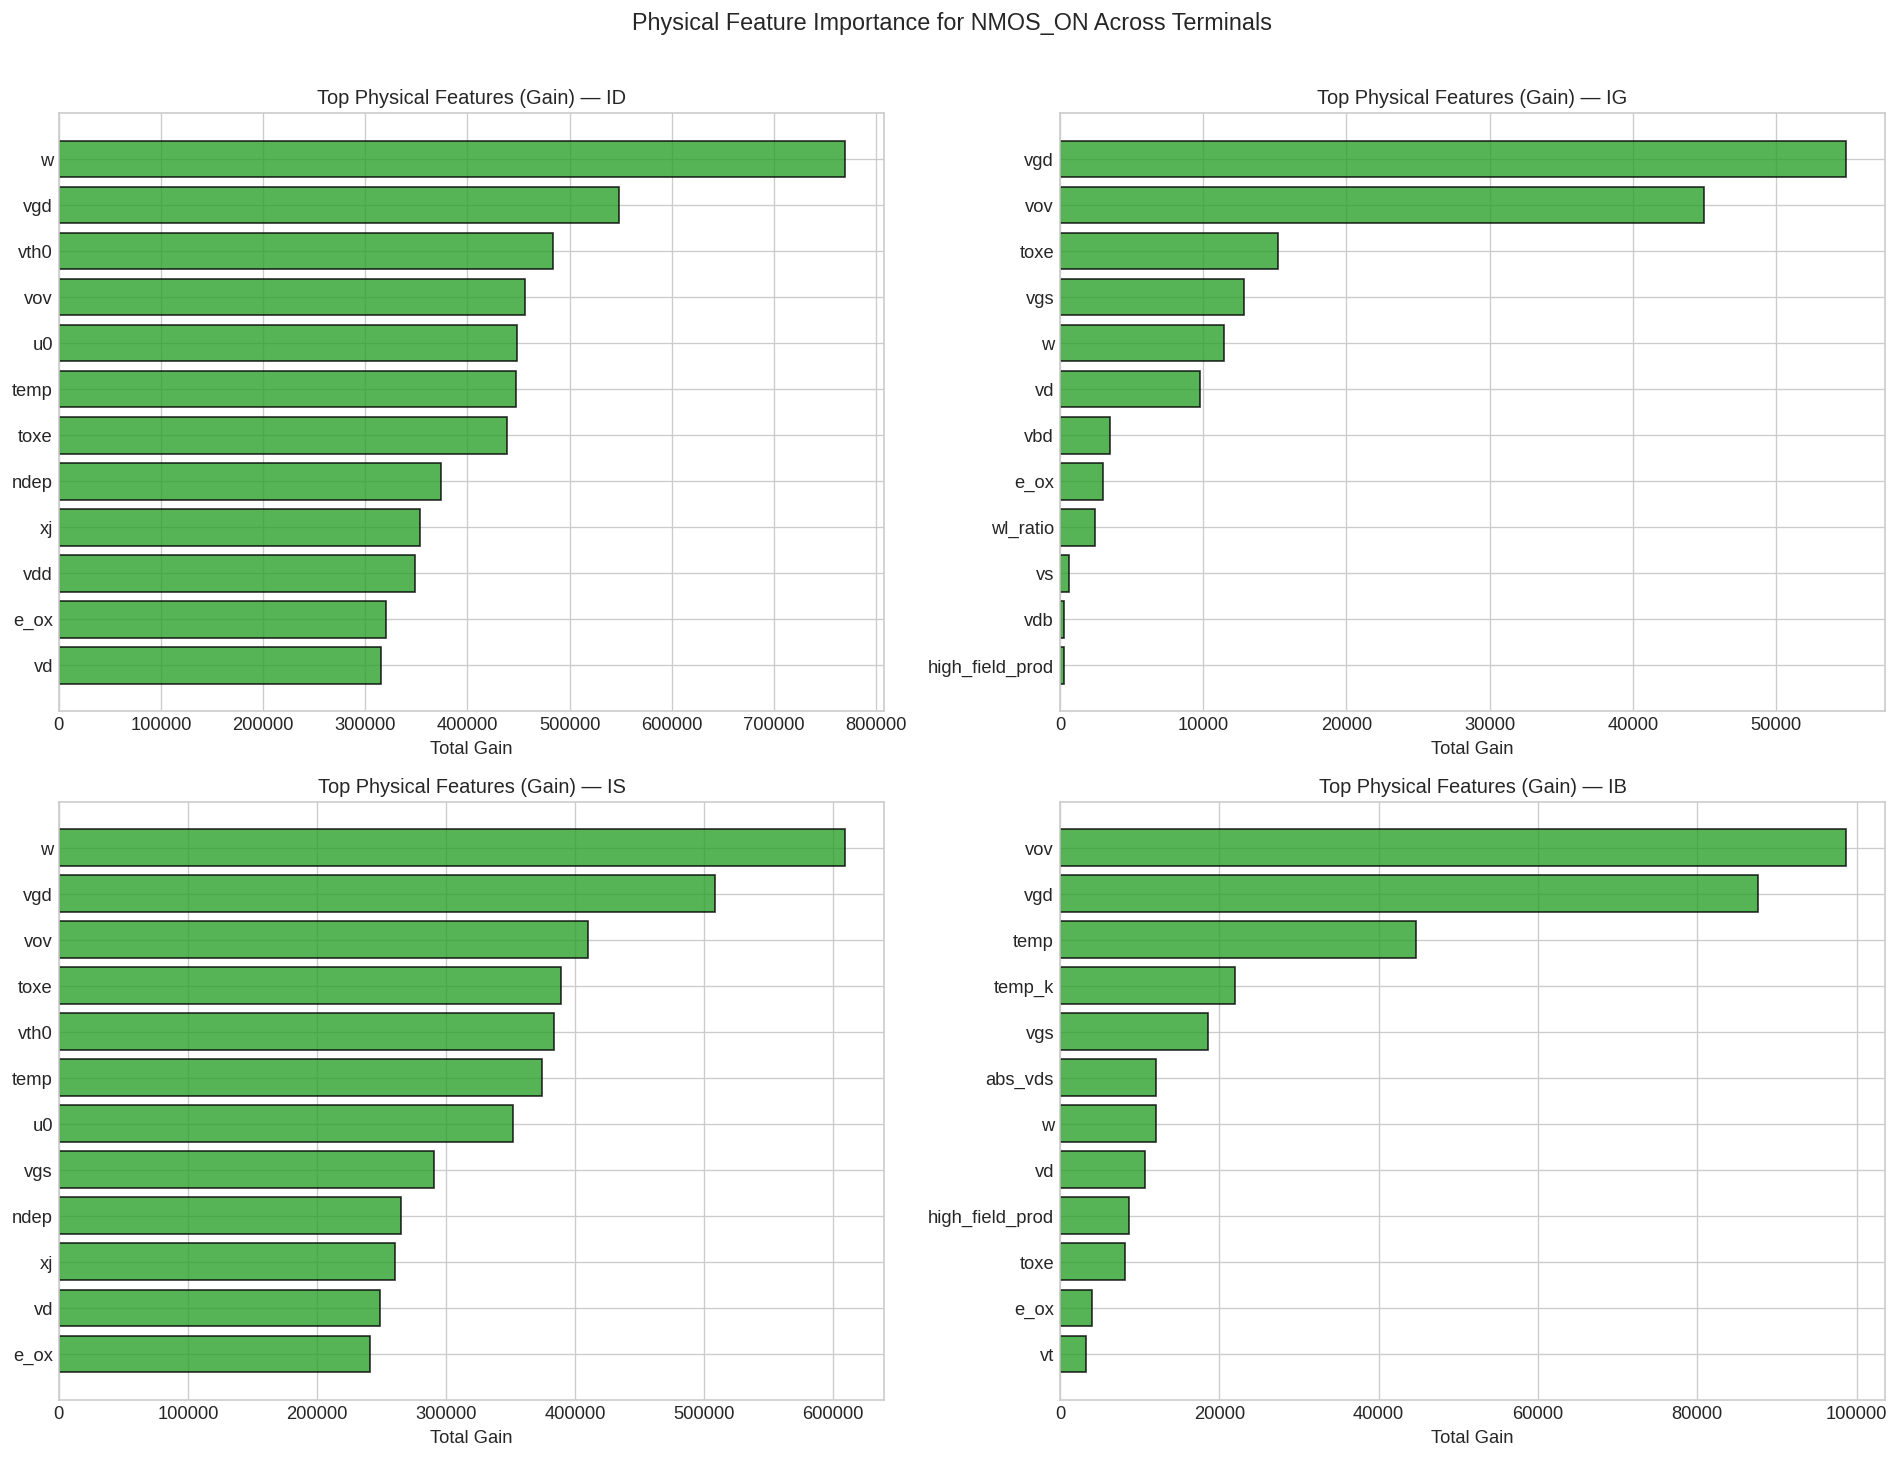

In [39]:
# 10. Feature Importance Analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, target in enumerate(TARGET_COLS):
    ax = axes[idx]
    model = trained_models[target]
    
    importance = model.booster_.feature_importance(importance_type='gain')
    feat_df = pd.DataFrame({'Feature': FEATURE_COLS, 'Importance': importance}).sort_values('Importance', ascending=True)
    
    # Plot top 12 most important features
    top_feats = feat_df.tail(12)
    ax.barh(top_feats['Feature'], top_feats['Importance'], color='#2ca02c', edgecolor='black', alpha=0.8)
    ax.set_title(f"Top Physical Features (Gain) — {target.upper()}", fontsize=12)
    ax.set_xlabel("Total Gain")

plt.suptitle(f"Physical Feature Importance for {CASE_NAME.upper()} Across Terminals", fontsize=14, y=1.01)
plt.tight_layout()

feat_plot_path = os.path.join(PLOTS_DIR, f"{CASE_NAME}_feature_importance.png")
plt.savefig(feat_plot_path, dpi=200, bbox_inches='tight')
print(f"✓ Saved Feature Importance Plot to: {feat_plot_path}")
plt.show()


In [40]:
# 11. Model Persistence & Metadata Saving
saved_files = {}
for target, model in trained_models.items():
    model_filename = f"lgbm_{CASE_NAME}_{target}.pkl"
    model_filepath = os.path.join(SAVED_MODELS_DIR, model_filename)
    joblib.dump(model, model_filepath)
    saved_files[target] = model_filepath
    print(f"✓ Saved model: {model_filepath}")

metadata = {
    "case_name": CASE_NAME,
    "feature_columns": FEATURE_COLS,
    "target_columns": TARGET_COLS,
    "epsilon": EPSILON,
    "model_type": "Fine-Tuned Conductance + Physics LightGBM Regressor",
    "training_date": time.strftime("%Y-%m-%d %H:%M:%S"),
    "val_metrics": metrics_val.to_dict(orient="records"),
    "test_metrics": metrics_test.to_dict(orient="records")
}

metadata_path = os.path.join(SAVED_MODELS_DIR, f"{CASE_NAME}_metadata.json")
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=4)
print(f"✓ Saved metadata and accuracy metrics: {metadata_path}")

print("\n" + "="*70)
print(f"SUMMARY FOR {CASE_NAME.upper()}:")
print(f"  All 4 terminal models saved in: {SAVED_MODELS_DIR}")
print(f"  Evaluation plots saved in     : {PLOTS_DIR}")
print("="*70)


✓ Saved model: ./saved_models/nmos_on/lgbm_nmos_on_id.pkl
✓ Saved model: ./saved_models/nmos_on/lgbm_nmos_on_ig.pkl
✓ Saved model: ./saved_models/nmos_on/lgbm_nmos_on_is.pkl
✓ Saved model: ./saved_models/nmos_on/lgbm_nmos_on_ib.pkl
✓ Saved metadata and accuracy metrics: ./saved_models/nmos_on/nmos_on_metadata.json

SUMMARY FOR NMOS_ON:
  All 4 terminal models saved in: ./saved_models/nmos_on
  Evaluation plots saved in     : ./plots/nmos_on


In [41]:
# 12. Inference Pipeline Helper (Predict Any PVT Vector)
def predict_leakage_currents(raw_pvt_dict):
    """
    Predicts (Id, Ig, Is, Ib) in Amperes for an input dictionary containing the 12 base PVT parameters.
    Automatically computes derived physical features, evaluates conductance/log models,
    and applies Kirchhoff Current Law projection.
    """
    row = pd.Series(raw_pvt_dict)
    
    # 1. Compute 16 derived physical features
    row['vds'] = row['vd'] - row['vs']
    row['abs_vds'] = abs(row['vds'])
    row['vgs'] = row['vg'] - row['vs']
    row['vgd'] = row['vg'] - row['vd']
    row['vbs'] = row['vb'] - row['vs']
    row['vbd'] = row['vb'] - row['vd']
    row['vov'] = row['vgs'] - row['vth0']
    row['temp_k'] = row['temp'] + 273.15
    row['vt'] = 8.617333e-5 * row['temp_k']
    row['wl_ratio'] = row['w'] / 22e-9
    row['e_ox'] = (row['vg'] - row['vb']) / row['toxe']
    
    row['vdb'] = row['vd'] - row['vb']
    row['vsb'] = row['vs'] - row['vb']
    row['high_field_prod'] = row['abs_vds'] * max(row['vov'], 0.0)
    row['depletion_drain'] = np.sqrt(max(0.7 + row['vdb'], 1e-3))
    row['depletion_source'] = np.sqrt(max(0.7 + row['vsb'], 1e-3))
    
    input_df = pd.DataFrame([row])[FEATURE_COLS]
    
    # 2. Load models and predict
    loaded = {t: joblib.load(os.path.join(SAVED_MODELS_DIR, f"lgbm_{CASE_NAME}_{t}.pkl")) for t in TARGET_COLS}
    
    # Reconstruct Id & Is via conductance
    vds = row['vds']
    abs_vds = row['abs_vds']
    pred_id = np.sign(vds) * abs_vds * (10 ** loaded['id'].predict(input_df)[0])
    pred_is = -np.sign(vds) * abs_vds * (10 ** loaded['is'].predict(input_df)[0])
    
    # Reconstruct Ig & Ib
    pred_ig = 1.0 * (10 ** loaded['ig'].predict(input_df)[0])
    pred_ib = -1.0 * (10 ** loaded['ib'].predict(input_df)[0])
    
    # 3. Apply KCL projection
    kcl_err = pred_id + pred_ig + pred_is + pred_ib
    return {
        'ID': pred_id - 0.25 * kcl_err,
        'IG': pred_ig - 0.25 * kcl_err,
        'IS': pred_is - 0.25 * kcl_err,
        'IB': pred_ib - 0.25 * kcl_err
    }

# Example query from test set:
sample_query = {k: X_test.iloc[0][k] for k in BASE_FEATURES}
predicted_currents = predict_leakage_currents(sample_query)

print("Inference query (Base PVT Corner):")
for k, v in sample_query.items():
    print(f"  {k:6s} : {v}")

print("\nPredicted Terminal Currents (KCL-Projected):")
for t, val in predicted_currents.items():
    print(f"  {t:2s} : {val:.4e} A")


Inference query (Base PVT Corner):
  vdd    : 0.8936020293459075
  temp   : 110.26399975446536
  w      : 1.0417885541813625e-07
  vd     : 0.3823223995232051
  vs     : 0.7147554081447095
  vg     : 0.8936020293459075
  vb     : 0.0
  vth0   : 0.3371141864483483
  toxe   : 6.957154452693981e-10
  ndep   : 1.0973702806238394e+19
  u0     : 0.0166975879174078
  xj     : 7.422391884756231e-09

Predicted Terminal Currents (KCL-Projected):
  ID : -5.5677e-05 A
  IG : -4.6548e-07 A
  IS : 5.6611e-05 A
  IB : -4.6801e-07 A
